In [175]:
#loading in the necessary packages 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import regex as re 
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.util import ngrams
nltk.download('wordnet')
from nltk.stem import WordNetLemmatizer
nltk.download('punkt_tab')
nltk.download('stopwords')
import json

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ilian\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ilian\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ilian\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Part 1: Data Cleaning with Regular Expressions

Use regular expressions to clean and standardize the dataset before deeper analysis.

In [153]:
#loading in the dataset 
product_reviews_df = pd.read_csv("C:/Users/ilian/Downloads/SI_345/DoU 3/product_reviews.csv")

#looking at the data to better understand it
product_reviews_df.head()

,review_id,product_name,category,rating,review_date,reviewer_location,review_text,helpful_votes,verified_purchase
0,REV-00001,Bluetooth Earbuds Pro,Electronics,5,2023-05-17,"Atlanta, GA",Will definitely buy again. Battery life is sol...,10,no
1,REV-00002,Data Science for Everyone,Books,3,2023-11-21,"Fort Worth, TX",Decent for the price. The author explains comp...,4,no
2,REV-00003,Cast Iron Skillet 10-inch,Kitchen,5,"May 27, 2022","Philadelphia, pa",Five stars isn't enough. Fits perfectly in my ...,16,true
3,REV-00004,Instant-Read Meat Thermometer,Kitchen,1,"April 7, 2022","Phoenix, Arizona",Returned it immediately. Heats up poorly — muc...,1,false
4,REV-00005,Air Fryer 5.8 Quart,Kitchen,1,"September 22, 2024","Miami, fl",Customer service was unhelpful. Cooks food poo...,2,true


Standardize the review_date column. Dates appear in multiple formats, including MM/DD/YYYY, Month DD, YYYY, and YYYY-MM-DD. Use re.sub() (or pandas .str.replace()) to convert all dates to ISO format (YYYY-MM-DD). Show that your conversion works by displaying a sample of before/after values.

In [154]:
#before 
print(product_reviews_df['review_date'] )

#converting the dates to the same format
product_reviews_df['review_date'] = pd.to_datetime(
    product_reviews_df['review_date'],
    format = 'mixed'
).dt.strftime('%Y-%m-%d')

#accounting for if months are spelled out 
months = {'jan' : '01', 'january': '01', 'feb': '02', 'february': '02',
          'mar': '03', 'march': '03',
          'apr': '04', 'april': '04',
          'may': '05', 
          'jun': '06', 'june': '06',
          'jul': '07', 'july': '07',
          'aug': '08', 'august': '08,',
          'sept': '09', 'september': '09',
          'oct': '10', 'october': '10',
          'nov': '11', 'november': '11',
          'dec': '12', 'december': '12'}

#converting the months using the dictionary 
for item in product_reviews_df['review_date']:
    if item.isalpha():
        item.lower()
        item = months[item]
        product_reviews_df['review_date'][item] = item 

#checking that they work using re.sub()
product_reviews_df['review_date'] =  product_reviews_df['review_date'].str.replace(
    r'(\d{1,2})[/,-](\d{1,2})[/,-](\d{4})', 
    r'\3-\1-\2', 
    regex=True
)
#this isn't owrking because its not accounting for the letters 

#after 
product_reviews_df['review_date'] 


0               2023-05-17
1               2023-11-21
2             May 27, 2022
3            April 7, 2022
4       September 22, 2024
               ...        
4995      October 25, 2022
4996              8/2/2024
4997             3-21-2022
4998          May 11, 2023
4999             1/29/2022
Name: review_date, Length: 5000, dtype: object


0       2023-05-17
1       2023-11-21
2       2022-05-27
3       2022-04-07
4       2024-09-22
           ...    
4995    2022-10-25
4996    2024-08-02
4997    2022-03-21
4998    2023-05-11
4999    2022-01-29
Name: review_date, Length: 5000, dtype: object


Standardize the verified_purchase column. Values appear as "Yes", "No", "TRUE", "FALSE", "true", "false", and occasionally "Y" or "N". Write a function using regex to normalize all values to True or False (boolean).

In [155]:
#creating the regex function 

def bool_verified_purchase(column):
    true_pattern = r'^[Yy]es|^[Tt]rue|^Y$'
    false_pattern = r'^[Nn]o|^[Ff]alse|^N$'

    column = column.str.replace(true_pattern, 'True', regex=True, flags=re.IGNORECASE)
    column = column.str.replace(false_pattern, 'False', regex=True, flags=re.IGNORECASE)
    
    return column == 'True'


#using it with the verified purchase column

bool_verified_purchase(product_reviews_df['verified_purchase'])

#applying the function to the actual column
product_reviews_df['verified_purchase'] = bool_verified_purchase(product_reviews_df['verified_purchase'])

product_reviews_df['verified_purchase']



0       False
1       False
2        True
3       False
4        True
        ...  
4995     True
4996     True
4997    False
4998    False
4999     True
Name: verified_purchase, Length: 5000, dtype: bool

Extract structured information from review_text. Write regex patterns to extract the following from each review where present:

Any email addresses mentioned (e.g., "contact us at support@brand.com")
Any URLs or website references
Any price mentions (e.g., "$24.99", "24 dollars")
For each, create a new column in the DataFrame containing the extracted values (or None if not found). Report how many reviews contained each type of extracted information.


In [156]:
#looking at the data
review_text = product_reviews_df['review_text']

#patterns 
email_pattern = r'\S+@\S+\.\S+'
url_pattern = r'https?://\S+|www\.\S+'
price_pattern = r'\$\d+(?:\.\{2})?'

#making each column and applying the regex patterns
product_reviews_df['emails_mentioned'] = product_reviews_df['review_text'].str.findall(email_pattern)
product_reviews_df['urls_mentioned'] = product_reviews_df['review_text'].str.findall(url_pattern)
product_reviews_df['prices_mentioned'] = product_reviews_df['review_text'].str.findall(price_pattern)

#checking results

product_reviews_df
#how many reviews have each type of extracted information 
#use value counts 
url_count = product_reviews_df['urls_mentioned'].str.len().value_counts()
price_count = product_reviews_df['prices_mentioned'].str.len().value_counts()
email_count = product_reviews_df['emails_mentioned'].str.len().value_counts()

print(url_count)
print(price_count)
print(email_count)


urls_mentioned
0    4591
1     409
Name: count, dtype: int64
prices_mentioned
0    3011
1    1974
2      15
Name: count, dtype: int64
emails_mentioned
0    4990
1      10
Name: count, dtype: int64


409 reviews contained urls, 1989 reviews mentioned prices, and 10 reviews mentioned emails. 


Clean the reviewer_location column. Standardize it so that all locations follow a City, ST format (two-letter uppercase state abbreviation). Remove any entries that can't be parsed into this format. Report how many rows were cleaned versus dropped.

In [157]:
#looking at the all of the locations in the data

#saving the original locations to a column so i can count the changes 
product_reviews_df['original_location'] = product_reviews_df['reviewer_location'] 


#
product_reviews_df['reviewer_location'].value_counts().to_string()

location_text = product_reviews_df['reviewer_location']

#make a state dictionary 
state_map = {
    'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR', 'California': 'CA',
    'Colorado': 'CO', 'Connecticut': 'CT', 'Delaware': 'DE', 'Florida': 'FL', 'Georgia': 'GA',
    'Hawaii': 'HI', 'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA',
    'Kansas': 'KS', 'Kentucky': 'KY', 'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD',
    'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS',
    'Missouri': 'MO', 'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH',
    'New Jersey': 'NJ', 'New Mexico': 'NM', 'New York': 'NY', 'North Carolina': 'NC',
    'North Dakota': 'ND', 'Ohio': 'OH', 'Oklahoma': 'OK', 'Oregon': 'OR', 'Pennsylvania': 'PA',
    'Rhode Island': 'RI', 'South Carolina': 'SC', 'South Dakota': 'SD', 'Tennessee': 'TN',
    'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT', 'Virginia': 'VA', 'Washington': 'WA',
    'West Virginia': 'WV', 'Wisconsin': 'WI', 'Wyoming': 'WY'
}
#have to make it so the ones with just months have the state too 

#regex pattern to identify 
loc_pattern = r'^(.*?)\s*,?\s*\b([a-zA-Z]{2})\b$'

def clean_location(text):
    if pd.isna(text): return text

    for full, abbr in state_map.items():
        text = re.sub(rf'\b{full}\b', abbr, text, flags=re.IGNORECASE)

    match = re.search(loc_pattern, text.strip())

    if match:
        city = match.group(1).title().strip()
        state = match.group(2).upper().strip()
        
        if city:
            return f"{city}, {state}"
    
    return text.title()

#applying the function 
product_reviews_df['reviewer_location'] = product_reviews_df['reviewer_location'].apply(clean_location)

#print(product_reviews_df['reviewer_location'].value_counts().to_string())

product_reviews_df['reviewer_location'] 

#this only worked for the ones that already have state in it, not just the city 

#mapping the unmatched cities to existing stuff in the data 
reference_df = product_reviews_df['reviewer_location'].str.extract(r'^(.*),\s*([A-Z]{2})$').dropna()
reference_df.columns = ['City', 'State']

# Drop duplicates to get a 1-to-1 mapping
city_to_state = reference_df.drop_duplicates('City').set_index('City')['State'].to_dict()

#making the 
def fill_missing_states(location):
    # If it's already in "City, ST" format, leave it alone
    if ',' in location:
        return location
    
    # If it's just a city name, look it up in our map
    if location in city_to_state:
        return f"{location}, {city_to_state[location]}"
    
    return location

# Apply the fix - matching them 
product_reviews_df['reviewer_location'] = product_reviews_df['reviewer_location'].apply(fill_missing_states)

#checking that it works 
print(product_reviews_df['reviewer_location'].value_counts().to_string())

#reporting how many were cleaned versus dropped 
cleaned_count = (product_reviews_df['original_location'] != product_reviews_df['reviewer_location']).sum()
unchanged_count = (product_reviews_df['original_location'] == product_reviews_df['reviewer_location']).sum()

print(f"Cleaned: {cleaned_count}")
print(f"Unchanged: {unchanged_count}")
product_reviews_df.shape[0]

reviewer_location
Houston, TX           208
Boston, MA            190
Philadelphia, PA      187
Indianapolis, IN      180
San Diego, CA         180
San Francisco, CA     177
Salt Lake City, UT    176
Miami, FL             176
Ny, NY                174
Austin, TX            173
Nashville, TN         173
San Jose, CA          173
Portland, OR          172
San Antonio, TX       171
Columbus, OH          170
Chicago, IL           167
Atlanta, GA           166
Los Angeles, CA       165
Richmond, VA          164
Fort Worth, TX        164
Denver, CO            158
Seattle, WA           158
Charlotte, NC         157
Dallas, TX            155
Detroit, MI           153
Minneapolis, MN       146
Ann Arbor, MI         145
Madison, WI           145
Phoenix, AZ           139
Jacksonville, FL      138
Cleaned: 2817
Unchanged: 2183


5000

There are 2817 rows that were cleaned and 2183 that were unchanged. This means that 2183 items were already in the City, ST form. There are 5000 rows total, so none of them were dropped because the other 2817 were cleaned. 

# Part 2: Text Normalization and Preprocessing
Build a reusable text cleaning pipeline for the review_text column.

Build a preprocessing function that takes a raw review string and returns a list of cleaned, normalized tokens. Your pipeline should:

- Lowercase all text
- Tokenize using NLTK's word_tokenize()
- Remove stopwords (using NLTK's English stopword list)
- Remove punctuation and non-alphabetic tokens
- Lemmatize using WordNetLemmatizer with POS-aware lemmatization (not just the default noun lemmatization)

In [158]:
def clean_tokens(review_str):

    #lowercase 
    item = review_str.lower()

    #tokenizing using word_tokenize
    tokenized_str = word_tokenize(item)

    #removing stopwords 
    stop_words = set(stopwords.words('english'))
    filtered_tokens = [word for word in tokenized_str if word not in stop_words]

    #remove punctuation and non-alphabetic tokens 
    only_alpha = [word for word in filtered_tokens if word.isalpha()]

    #lemmatize 
    lemmatizer = WordNetLemmatizer()
    cleaned_str = [lemmatizer.lemmatize(word) for word in only_alpha]
    
    return cleaned_str

Apply your pipeline to all reviews and store the cleaned token lists in a new column (cleaned_tokens).

In [159]:
#making a new column by applying the function
product_reviews_df['cleaned_tokens'] = product_reviews_df['review_text'].apply(lambda x: clean_tokens(x))

#checking to see if it worked 
product_reviews_df['cleaned_tokens'] 

0       [definitely, buy, battery, life, solid, charge...
1       [decent, price, author, explains, complex, ide...
2       [five, star, enough, fit, perfectly, small, ap...
3       [returned, immediately, heat, poorly, much, fa...
4       [customer, service, unhelpful, cook, food, poo...
                              ...                        
4995    [nothing, write, home, index, fine, make, easy...
4996    [fantastic, quality, price, compatible, laptop...
4997    [quality, outstanding, recommended, colleague,...
4998    [acceptable, impressive, waterproofing, accept...
4999    [absolutely, love, product, lightweight, great...
Name: cleaned_tokens, Length: 5000, dtype: object

Compare stemming vs. lemmatization on a sample of 5-10 reviews from the dataset. Show the differences side by side and briefly comment on which approach is more appropriate for this analysis and why.

In [160]:
#importing more stuff 
from nltk.stem import PorterStemmer, WordNetLemmatizer
#nltk.download('punkt')
#nltk.download('wordnet')
#nltk.download('omw-1.4')
#stemming 

#lemmatization 
sample_reviews = product_reviews_df['review_text'].dropna().head(5).tolist()

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

#comparison data 
comparison_data = []

for review in sample_reviews: 
    tokens = word_tokenize(review.lower())
    
    for word in tokens:
        # Only compare words where stemming and lemmatization differ
        stemmed = stemmer.stem(word)
        lemmatized = lemmatizer.lemmatize(word)
        
        if stemmed != lemmatized:
            comparison_data.append({
                'Original': word,
                'Stemmed': stemmed,
                'Lemmatized': lemmatized
            })

# 3. Show the differences in a DataFrame
diff_df = pd.DataFrame(comparison_data).drop_duplicates()
print(diff_df.head(15))

          Original     Stemmed      Lemmatized
0       definitely     definit      definitely
1          battery     batteri         battery
2          charges       charg          charge
3          quickly     quickli         quickly
4           beware       bewar          beware
5         explains     explain        explains
6       reasonably      reason      reasonably
7      recommended   recommend     recommended
8        colleague    colleagu       colleague
9              why         whi             why
10  well-organized  well-organ  well-organized
11         average      averag         average
13       perfectly   perfectli       perfectly
14       apartment       apart       apartment
15            easy        easi            easy


Lemmatizing makes more sense for this column because it more accurately captures the words. The stemming shortens the words in a way that doesn't make sense, because it's processing what it thinks is the 'root' of the word and cutting off the ending, but that doesn't make sense in the context of these words. For example, stemming changes 'well-organized' to 'well-organ' while lemmatizing leaves it the same. The lemmatizing doesn't really change anything, so I'm not sure what it's doing in this case, but the stemming doesn't make sense for the words in this context. 

Create a domain-specific stopword list. Examine the most frequent tokens in the cleaned corpus. Identify 10-15 words that appear frequently but are specific to the review genre rather than meaningful content (e.g., "product", "item", "bought"). Add these to your stopword list and re-run your pipeline. Show how the top-30 word frequency list changes.

In [161]:
#examining the most frequent tokens by creating a dictionary (order of most mentioned)
frequent_tokens = {}
for review_words in product_reviews_df['cleaned_tokens']: 
    for word in review_words:
        if word in frequent_tokens:
            frequent_tokens[word] += 1 
        else:
            frequent_tokens[word] = 1
frequent_tokens = dict(sorted(frequent_tokens.items(),  key=lambda item: item[1], reverse=True))
print(frequent_tokens)

#creating a custom stop words list 
custom_stopwords = ['buy','definitely', 'buyer', 'alongside', 'customer', 
                    'paid', 'purchase', 'every', 'considering', 'overall',
                    'price', 'could', 'everything', 'explains', 'felt']

#re-calculating the tokens in each review
new_frequent_tokens = {}
for review_list in product_reviews_df['cleaned_tokens']:
    filtered_review = [word for word in review_list if word not in custom_stopwords]
    #print(filtered_review)

#changing list of top 30 frequency words based on filtered reviews
    for word in filtered_review: 
        if word in new_frequent_tokens:
            new_frequent_tokens[word] += 1 
        else:
            new_frequent_tokens[word] = 1
    new_frequent_tokens = dict(sorted(new_frequent_tokens.items(),  key=lambda item: item[1], reverse=True))
#print(new_frequent_tokens)

#limiting this to the top 30 
limited_dict = {k: new_frequent_tokens[k] for k in list(new_frequent_tokens)[:30]}
print(limited_dict)

#updating the actual column (did this after the rest bc i realized i need it for the next part)
product_reviews_df['cleaned_tokens'] = product_reviews_df['cleaned_tokens'].apply(
    lambda x: [word for word in x if word not in custom_stopwords]
)

{'paid': 1962, 'great': 1917, 'quality': 1461, 'feel': 1374, 'easy': 1102, 'solid': 1051, 'work': 937, 'purchase': 870, 'felt': 805, 'fit': 785, 'overall': 756, 'worth': 753, 'skin': 740, 'considering': 682, 'could': 676, 'okay': 673, 'construction': 653, 'recommend': 641, 'outstanding': 638, 'way': 618, 'expectation': 601, 'price': 596, 'well': 594, 'highly': 587, 'every': 578, 'setup': 554, 'buy': 552, 'exceeded': 538, 'style': 529, 'impressive': 475, 'perfectly': 474, 'one': 471, 'love': 459, 'held': 449, 'backpacking': 449, 'trip': 449, 'pack': 447, 'alongside': 447, 'gear': 447, 'durability': 445, 'superb': 434, 'good': 432, 'tested': 431, 'temperature': 431, 'degree': 431, 'worked': 431, 'waterproofing': 427, 'kept': 427, 'everything': 427, 'dry': 427, 'heavy': 427, 'rain': 427, 'lightweight': 425, 'disappointed': 425, 'month': 423, 'excellent': 420, 'strap': 417, 'dig': 417, 'shoulder': 417, 'two': 408, 'week': 408, 'writing': 407, 'follow': 407, 'reliable': 405, 'recommended': 

You can see in the output here how the top-30 most frequent words list changes. Most of the words in the second list are positive, or about the quality and construction of the product. In the first dictionary, the top word was 'paid', which as an individual word tells nothing meaningful about the review. 

# Part 3: Frequency Analysis and Linguistic Features
Analyze linguistic patterns across the review corpus.

Word frequency analysis. Using your cleaned tokens, compute the top 30 most frequent words overall. Then compute the top 20 most frequent words separately for each rating level (1-star through 5-star). Visualize the results (a bar chart or heatmap works well here — use your judgment).



{
    "1": {
        "great": 167,
        "easy": 149,
        "feel": 146,
        "terrible": 125,
        "work": 119,
        "flimsy": 118,
        "weak": 116,
        "poorly": 110,
        "unreliable": 103,
        "subpar": 102,
        "quality": 102,
        "barely": 101,
        "unreliably": 98,
        "disappointing": 97,
        "mediocre": 94,
        "worth": 92,
        "fit": 89,
        "inconsistently": 84,
        "disappointed": 84,
        "one": 83
    },
    "2": {
        "great": 118,
        "feel": 116,
        "terrible": 107,
        "easy": 101,
        "quality": 88,
        "flimsy": 88,
        "weak": 81,
        "mediocre": 79,
        "work": 76,
        "poorly": 74,
        "fit": 74,
        "barely": 72,
        "subpar": 69,
        "worth": 69,
        "poor": 69,
        "weakly": 64,
        "unreliable": 61,
        "unreliably": 60,
        "disappointing": 58,
        "issue": 53
    },
    "3": {
        "okay": 212,
        "avera

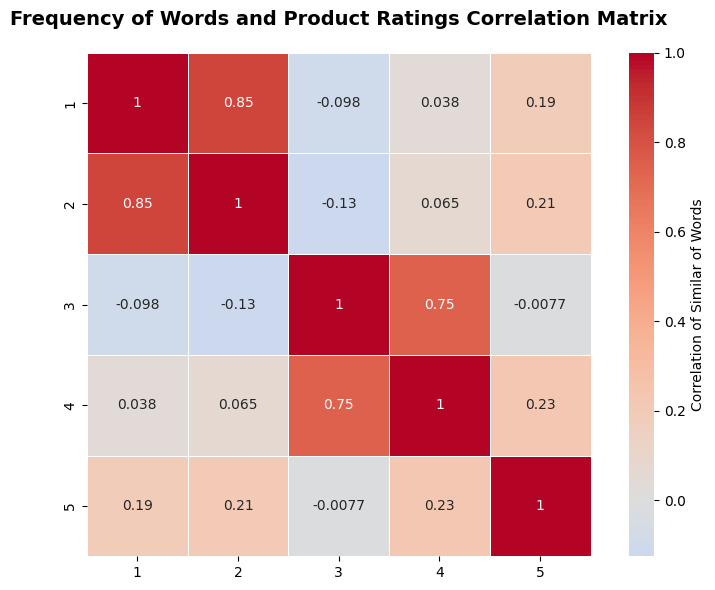

In [162]:
#computing most frequent words in cleaned tokens - making it easier to look at 
#print(json.dumps(limited_dict, indent=4))

#separated by each rating 
tokencount_by_rating = product_reviews_df['cleaned_tokens'].groupby(product_reviews_df['rating']).sum()

tokencount_by_rating

rating_dict = {}
i = 1
for item in tokencount_by_rating:
    word_count = {}
    for word in item: 
        if word in word_count: 
            word_count[word] += 1 
        else:
            word_count[word] = 1 
    rating_dict[i] = word_count 
    i += 1

#updating the dictionary based on the top 20 and sorting them  
for item in rating_dict:
    raw_counts = rating_dict[item]
    
    sorted_rating = dict(sorted(raw_counts.items(), key=lambda x: x[1], reverse=True))
    
    limited_rating = {k: sorted_rating[k] for k in list(sorted_rating)[:20]}
   
    rating_dict[item] = limited_rating


#updated dict with a format thats easy to see 
print(json.dumps(rating_dict, indent=4)) 

#creating a df so i can make a plot 
df_plot = pd.DataFrame(rating_dict).fillna(0)

#bar chart visualizing the output
#need to change it so its a correaltion, not counting 
corr_matrix = df_plot.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, 
            annot=True,           # Show values in cells
            cmap='coolwarm',      # Color scheme
            center=0,             # Center colormap at 0
            square=True,          # Make cells square
            linewidths=0.5,         # Lines between cells
            cbar_kws={'label': 'Correlation of Similar of Words'})

plt.title('Frequency of Words and Product Ratings Correlation Matrix', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

This heatmap shows that ratings with 1 and 2 stars and 3 and 4 stars have similar words to each other. Something surprising is that 1 and 5 star ratings have 0.19 correlation of similar words with each other. I would expect 1 and 5 star ratings to have very different words, but this could be due to the fact they both contain 'extreme' words like 'really' bad or 'really' good. 

N-gram analysis. Extract the top 20 bigrams and top 10 trigrams from the full cleaned corpus. Then compare: what are the most common bigrams in 1-star reviews versus 5-star reviews? Present your findings clearly.

In [174]:
#N-gram analysis
#getting the individual 
#print(product_reviews_df['review_text'])

# Find common bigrams (2-word phrases)
from nltk.collocations import BigramCollocationFinder, TrigramCollocationFinder


#creating a full corpus 
full_corpus = [word for review in product_reviews_df['cleaned_tokens'] for word in review]

# Create bigram finder
finder = BigramCollocationFinder.from_words(full_corpus)

# Get top bigrams by frequency
print("Most frequent bigrams:")

bigram_data = [
    (" ".join(bigram), freq)
    for bigram, freq in finder.ngram_fd.most_common(20)
]

bigram_df = pd.DataFrame(bigram_data, columns=['Bigram', 'Frequency'])

print(bigram_df)
#get top trigrams by frequency 
trigram_finder = TrigramCollocationFinder.from_words(full_corpus)
top_10_trigrams = trigram_finder.ngram_fd.most_common(10)
print("Most frequent trigrams:")
trigram_data = [
    (" ".join(trigram), freq)
    for trigram, freq in trigram_finder.ngram_fd.most_common(10)
]

trigram_df = pd.DataFrame(trigram_data, columns=['Trigram', 'Frequency'])

print(trigram_df)

Most frequent bigrams:
                   Bigram  Frequency
0        highly recommend        587
1    exceeded expectation        538
2        backpacking trip        449
3               pack gear        447
4      tested temperature        431
5      temperature degree        431
6           degree worked        431
7            worked great        431
8                kept dry        427
9               dry heavy        427
10             heavy rain        427
11           dig shoulder        417
12               two week        408
13          writing style        407
14            easy follow        407
15  recommended colleague        400
16   colleague understand        400
17              little go        391
18               long way        391
19        great companion        390
Most frequent trigrams:
                            Trigram  Frequency
0         tested temperature degree        431
1         temperature degree worked        431
2               degree worked great

In [178]:
#comparing the most common bigrams in 1 star versus 5 star reviews 

#splitting the date by stars 
one_star_reviews = product_reviews_df[product_reviews_df['rating'] == 1]['cleaned_tokens']
five_star_reviews = product_reviews_df[product_reviews_df['rating'] == 5]['cleaned_tokens']

#flattening the tokens so i can go through each 
one_star = [word for tokens in one_star_reviews for word in tokens]
five_star = [word for tokens in five_star_reviews for word in tokens]

#getting bigrams for each 
# 1-star bigrams
one_star_bigrams = list(ngrams(one_star, 2))

# 5-star bigrams
five_star_bigrams = list(ngrams(five_star, 2))

#counting the most frequnet 
one_star_bigram_freq = pd.Series(one_star_bigrams).value_counts().head(10)
five_star_bigram_freq = pd.Series(five_star_bigrams).value_counts().head(10)

print(f"One Star Bigram Frequency: \n{one_star_bigram_freq}")
print(f"\nFive Star Bigram Frequency: \n{five_star_bigram_freq}")


One Star Bigram Frequency: 
(two, week)              82
(make, easy)             57
(easy, reference)        57
(worked, great)          51
(degree, worked)         51
(temperature, degree)    51
(tested, temperature)    51
(easy, follow)           50
(writing, style)         50
(faster, old)            50
Name: count, dtype: int64

Five Star Bigram Frequency: 
(highly, recommend)        354
(exceeded, expectation)    325
(backpacking, trip)        237
(pack, gear)               233
(kept, dry)                225
(heavy, rain)              225
(dry, heavy)               225
(degree, worked)           212
(temperature, degree)      212
(worked, great)            212
Name: count, dtype: int64


The most common bigrams in one star reviews are all less common than the bigrams in the five star reviews. The five star bigrams include very positive ones, like (highly, recommend) and (exceeded, expectation), which was expected, but surprisingly the one star reviews don't contain frequent bigrams that are negative. The most frequent for one star reviews is (two, week), which could be about the time it took to ship or how long the product lasted, but it is not immediately clear that it is negative. 

Named Entity Recognition. Apply NLTK's ne_chunk() to a sample of at least 200 reviews. Extract all named entities and report:

The most frequently mentioned ORGANIZATION entities
The most frequently mentioned PERSON entities (if any)
Any patterns you notice about what types of entities appear most

In [164]:
#importing the packages 
from nltk import ne_chunk
from nltk import pos_tag

#def entities function (from the lectures)
def extract_entities(series):
    entities = {'PERSON': {}, 'ORGANIZATION': {}, 'GPE': {}, 'LOCATION': {}}
    for text in series:
        if not isinstance(text, str): continue

        tokens = word_tokenize(text)
        tagged = pos_tag(tokens)
        chunked = ne_chunk(tagged)
        
        for chunk in chunked: 
            if hasattr(chunk, 'label'):
                entity_type = chunk.label()
                entity_text = ' '.join(c[0] for c in chunk)
                
                if entity_type in entities: 
                    if entity_text in entities[entity_type]:
                        entities[entity_type][entity_text]+= 1
                    else: 
                        entities[entity_type][entity_text]= 1
    return entities

#getting the sample of 200 reviews 
sample_reviews = product_reviews_df['review_text'].dropna().sample(200, random_state=42)

#editing how the entities are categorized 

#applying the function
entities = extract_entities(sample_reviews)

#counting the most frequent ones 
print("Most frequent ORGANIZATION entities:")
org_sorted = sorted(entities['ORGANIZATION'].items(), key=lambda x: x[1], reverse=True)
for entity, count in org_sorted[:10]:
    print(f"{entity}: {count}")

print("\nMost frequent PERSON entities:")
person_sorted = sorted(entities['PERSON'].items(), key=lambda x: x[1], reverse=True)
for entity, count in person_sorted[:10]:
    print(f"{entity}: {count}")




Most frequent ORGANIZATION entities:
Bluetooth: 18
LOVE: 3
WONDERFUL: 3
www.techsupport.example.com: 2
GREAT: 1

Most frequent PERSON entities:
Buyer: 19
Sound: 16
Easy: 16
Noticed: 13
Battery: 13
Perfect: 11
Cooks: 10
Code: 9
Highly: 8
Setup: 8


Most of the organizations and people in the named entities weren't actually organizations or people. The most frequent 'person' mentioned (probably the only one that counts as a person) was 'Buyer'. The most frequent organization was Bluetooth, which may not count as an organization. The only other one in the entities dictionary that may count as an actual organization was www.techsupport.example.com. This shows that naming entities is not super effective for this dataframe, maybe because there are no people or organization entities, or maybe because the entities algorithm isn't applicable to this dataframe. 

Vocabulary richness analysis. Calculate the Type-Token Ratio (TTR = unique tokens / total tokens) for reviews in each product category. Do some categories produce richer, more varied language? Discuss what this might mean.

In [165]:
#defining a function that calculates the ratio 
def TTR(series):
    all_tokens = []
    
    for text in series.dropna():
        tokens = word_tokenize(text.lower())
        all_tokens.extend(tokens)
    
    unique_tokens = set(all_tokens)
    
    if len(all_tokens) == 0:
        return 0
    
    return len(unique_tokens) / len(all_tokens)

#applying the function to the reviews based on category 
ttr_by_category = (
    product_reviews_df.groupby('category')['review_text']
    .apply(TTR)
    .reset_index(name='TTR')
)

print(ttr_by_category)

      category       TTR
0       Beauty  0.023186
1        Books  0.011940
2  Electronics  0.013358
3      Kitchen  0.021434
4      Outdoor  0.020324


We can see in the TTR by category that beauty produces the highest category. This may produce more varied language because it's a wide category that includes hair, makeup, skincare, nails, and a large variety of other products. Additionally, there are a variety of problems or compliments that someone could be leaving about a beauty product because of the variety of products. Books has the least amount of variety because there are not many problems there can be with a book as a product, the problems would be with the content of the book. Also, not many people order books online that they don't already want so people are likely not leaving a lot of reviews for books. 

# Part 4: Sentiment Analysis
Apply VADER sentiment analysis to understand the emotional landscape of the reviews.

Compute VADER sentiment scores for all reviews. Add the four VADER scores (pos, neg, neu, compound) as new columns to your DataFrame.

In [166]:
#importing vader package 
nltk.download('vader_lexicon', quiet=True)
from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

#creating a sentiment analysis function

def get_sentiment_scores(text):
    if not isinstance(text, str):
        return {'neg': 0, 'neu': 0, 'pos': 0, 'compound': 0}
    
    return sia.polarity_scores(text)

#applying the function to the data
sentiment_scores = product_reviews_df['review_text'].apply(get_sentiment_scores)

#splitting it into columns 
sentiment_df = sentiment_scores.apply(pd.Series)

#updating the df to include the four columns 
product_reviews_df = pd.concat([product_reviews_df, sentiment_df], axis=1)

#checking results 
print(product_reviews_df[['review_text', 'compound', 'neg', 'neu', 'pos']].head())

                                         review_text  compound    neg    neu  \
0  Will definitely buy again. Battery life is sol...    0.5499  0.056  0.723   
1  Decent for the price. The author explains comp...    0.2023  0.000  0.924   
2  Five stars isn't enough. Fits perfectly in my ...    0.5158  0.091  0.701   
3  Returned it immediately. Heats up poorly — muc...    0.7003  0.069  0.733   
4  Customer service was unhelpful. Cooks food poo...    0.5106  0.000  0.918   

     pos  
0  0.221  
1  0.076  
2  0.208  
3  0.198  
4  0.082  


Validate against star ratings. Create a visualization showing how compound sentiment scores relate to star ratings. Do 5-star reviews actually score more positive than 3-star reviews? Are there interesting outliers? Identify and examine 3-5 reviews that have unexpected sentiment/rating combinations (e.g., high stars but negative sentiment, or vice versa) and discuss possible explanations.

rating
1    0.164020
2    0.124493
3    0.482298
4    0.654142
5    0.800880
Name: compound, dtype: float64


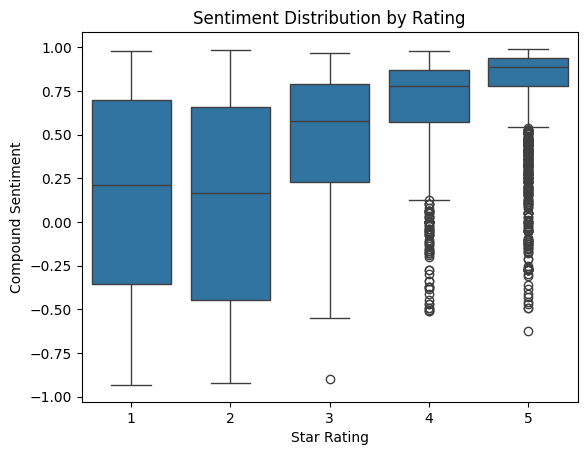

In [167]:
#creating a group by object for the compound score and star ratings
sentiment_by_rating = product_reviews_df.groupby('rating')['compound'].mean()

print(sentiment_by_rating)

#mkaing a box plot for it (because box plots show outliers )

sns.boxplot(x='rating', y='compound', data=product_reviews_df)

plt.title('Sentiment Distribution by Rating')
plt.xlabel('Star Rating')
plt.ylabel('Compound Sentiment')
plt.show()

5-star reviews do score more positive than 3 star reviews, which is shown by the box plot showing that the distribution for 5-star ratings is much narrower and more positive than for 3-star reviews. There are interesting outliers in the 5 star and 4 star rating sections-- some of the ratings score negatively in the sentiment analysis even though they are rated very well:

Looking at reviews that show high rating but low sentiment: 


In [ ]:
#filtering the reviews 
high_rating_low_sentiment = product_reviews_df[
    (product_reviews_df['rating'] >= 4) & 
    (product_reviews_df['compound'] < 0)
]

#printing the reviews to look at (so i can read the text)

for i, row in high_rating_low_sentiment.head(5).iterrows():
    print(f"\nProduct: {row['product_name']}")
    print(f"Rating: {row['rating']}, Compound: {row['compound']}")
    print(f"Review:\n{row['review_text']}")
    print("-" * 80)


Product: Solar Lantern Rechargeable
Rating: 4, Compound: -0.1278
Review:
Setup was a breeze. Held up reasonably on a week-long backpacking trip. Waterproofing is decent — kept everything dry in heavy rain. Tested it at temperatures down to 32 degrees — worked great. Disappointed but not surprised.
--------------------------------------------------------------------------------

Product: Insulated Water Bottle 32oz
Rating: 5, Compound: -0.1278
Review:
Exceeded my expectations in every way. Tested it at temperatures down to 29 degrees — worked great. Paid $66.86 — reasonable considering the durability. Disappointed but not surprised.
--------------------------------------------------------------------------------

Product: Vitamin C Serum 20%
Rating: 5, Compound: -0.25
Review:
Solid construction, feels premium. Skin feels solid after just a few uses. Non-greasy formula absorbs consistently. I paid $19.44 for it and felt it was a steal. Will be returning this.
---------------------------

Three reviews that show high rating but low compound score: 

- Solar Lantern Rechargeable: This review got 4 stars, but a compound score of -0.1278. This is likely because at the end of the review the person adds "Disappointed but not surprised", despite the rest of the review reading positive. It doesn't seem logical that the person added this negative comment at the end based on the rest of the positive stuff they wrote, but this is likely why the compound score is negative. 

- Mechanical Keyboard TKL: This review got 4 stars, but a compound score of -0.2732. This is for a similar reason-- conflicting messages in the review. The person adds "Buyer beware" at the end of the review, after saying it "exceeded [their] expectations in every way". This is another example of the review itself including mixed language, so it is reasonable for the VADER analysis to analyze this as a negative review despite the high star rating, because the review itself is confusing. 

- Vitamin C Serum 20%: This review got 5 stars, but a compound score of -0.25. This is likely because at the end the person said "will be returning this", despite saying positive stuff about the product in the rest of the review. Also the part that says "Skin feels solid after just a few uses" may be confusing for the VADER analysis, because it is unclear whether that is a positive or negative thing. I believe it is positive based on the 5 star rating, but adding "will be returning this" at the end makes it unclear. 

These could all be user mistakes in wording, or accidentally giving the wrong star rating, but the VADER analysis is unable to know that, which is why we get these outliers with high ratings but low compound scores. 

Sentiment by category. Compare average sentiment scores across product categories. Are some categories more polarized (high variance in compound scores) than others? Visualize this comparison.

      category  avg_sentiment
0       Beauty       0.626410
1        Books       0.747489
2  Electronics       0.473685
3      Kitchen       0.621350
4      Outdoor       0.563260
      category  sentiment_variance
0       Beauty            0.173110
1        Books            0.097914
2  Electronics            0.248803
3      Kitchen            0.154792
4      Outdoor            0.233846


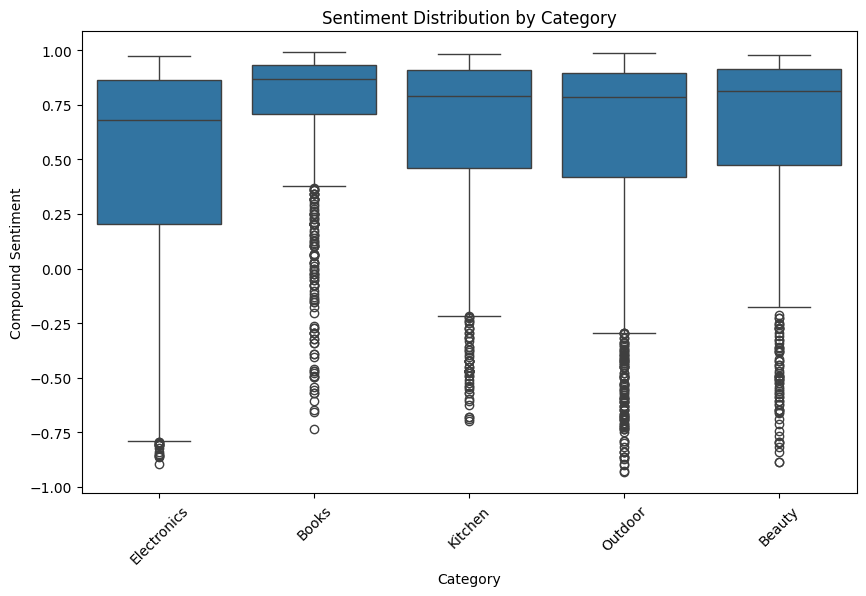

In [169]:
#grouping sentiment scores by category 
sentiment_by_category = (
    product_reviews_df.groupby('category')['compound']
    .mean()
    .reset_index(name='avg_sentiment')
)

print(sentiment_by_category)

#comparing by polarization(variance)
variance_by_category = (
    product_reviews_df.groupby('category')['compound']
    .var()
    .reset_index(name='sentiment_variance')
)

print(variance_by_category)

#making a boxplot 
plt.figure(figsize=(10, 6))

sns.boxplot(x='category', y='compound', data=product_reviews_df)

plt.xticks(rotation=45)
plt.title('Sentiment Distribution by Category')
plt.ylabel('Compound Sentiment')
plt.xlabel('Category')
plt.show()


Yes, some categories are more polarized than others. The books category has the least variance, as there are mostly high compound sentiment scores in the Books category, and little variation from that. The category with the most variance is Electronics. However, all of the categories have lots of outliers on the lower end of the compound sentiment spectrum. 

Sentiment vs. helpfulness. Explore the relationship between a review's sentiment and its helpful_votes. Do more extreme reviews (very positive or very negative compound scores) tend to receive more helpful votes? Create a visualization and discuss your findings.

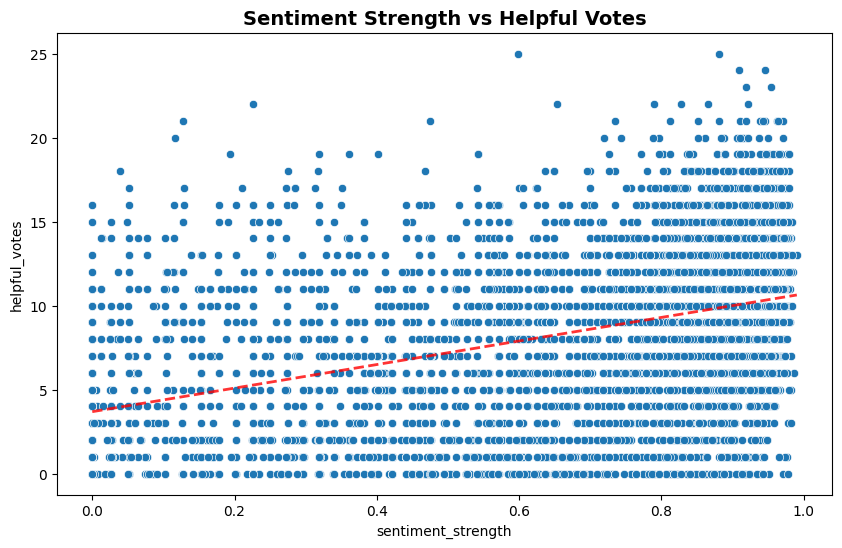

In [170]:
#creating a variable for extreme reviews 
product_reviews_df['sentiment_strength'] = product_reviews_df['compound'].abs()

#creating a scatterplot to visualize these findings 
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data= product_reviews_df, 
                x='sentiment_strength', 
                y='helpful_votes', 
                )

# Adding a trend line 
z = np.polyfit(product_reviews_df['sentiment_strength'], product_reviews_df['helpful_votes'], 1)
p = np.poly1d(z)
x_line = np.linspace(product_reviews_df['sentiment_strength'].min(), 
                     product_reviews_df['sentiment_strength'].max(), 100)
ax.plot(x_line, p(x_line), "r--", linewidth=2, alpha=0.8, label='Trend line')

plt.title('Sentiment Strength vs Helpful Votes', fontsize=14, fontweight='bold')
plt.show()

Based on the graph, there is a slight positive relationship between sentiment strength and how helpful the review is. This means that the more extreme votes (really positive and really negative) get slightly more helpful votes than the reviews that are less extreme. 

# Part 5: Integrated Analysis Pipeline
Build a comprehensive analysis that brings together regex, NLP, and sentiment techniques to answer a specific question of your choosing.

The question I'm focusing on:

“What distinguishes ‘helpful’ reviews from ‘unhelpful’ reviews linguistically?”

Build your analysis using at least three of the following techniques covered in Lectures 10-14:

I'm going to use: 
Tokenization and preprocessing pipeline, 
Frequency or n-gram analysis, and 
Sentiment analysis (VADER)

In [171]:
#creating a threshold for helpful versus unhelpful 
product_reviews_df['helpful_label'] = product_reviews_df['helpful_votes'].apply(
    lambda x: 'helpful' if x > 5 else 'unhelpful'
)

#tokenization and preprocessing 
helpful_tokens = product_reviews_df[product_reviews_df['helpful_label'] == 'helpful']['cleaned_tokens']
unhelpful_tokens = product_reviews_df[product_reviews_df['helpful_label'] == 'unhelpful']['cleaned_tokens']

#frequnecy or n-gram analysis 
# flattening helpful and unhelpful words so i can count them 
helpful_words = [word for tokens in helpful_tokens for word in tokens]
unhelpful_words = [word for tokens in unhelpful_tokens for word in tokens]

# convert to Series and count
helpful_word_freq = pd.Series(helpful_words).value_counts().head(10)
unhelpful_word_freq = pd.Series(unhelpful_words).value_counts().head(10)

print("Helpful words:\n", helpful_word_freq)
print("\nUnhelpful words:\n", unhelpful_word_freq)

#sentiment analysis (VADER)
from nltk.util import ngrams

# helpful bigrams
helpful_bigrams = [
    bigram
    for tokens in helpful_tokens
    for bigram in list(ngrams(tokens, 2))
]

# unhelpful bigrams
unhelpful_bigrams = [
    bigram
    for tokens in unhelpful_tokens
    for bigram in list(ngrams(tokens, 2))
]

# counting them 
helpful_bigram_freq = pd.Series(helpful_bigrams).value_counts().head(10)
unhelpful_bigram_freq = pd.Series(unhelpful_bigrams).value_counts().head(10)

print("Helpful bigrams:\n", helpful_bigram_freq)
print("\nUnhelpful bigrams:\n", unhelpful_bigram_freq)
 


Helpful words:
 great           1530
quality         1140
feel            1003
solid            929
easy             779
work             680
outstanding      619
fit              553
construction     541
skin             540
Name: count, dtype: int64

Unhelpful words:
 great       387
feel        371
easy        323
quality     321
work        257
worth       239
fit         232
terrible    224
skin        200
one         195
Name: count, dtype: int64
Helpful bigrams:
 (highly, recommend)        476
(exceeded, expectation)    446
(backpacking, trip)        333
(pack, gear)               320
(pricey, fair)             312
(kept, dry)                311
(temperature, degree)      311
(degree, worked)           311
(tested, temperature)      311
(worked, great)            311
Name: count, dtype: int64

Unhelpful bigrams:
 (two, week)              161
(pack, gear)             127
(tested, temperature)    120
(dig, shoulder)          120
(worked, great)          120
(degree, worked)       

Present your findings clearly. Include at least two visualizations that support your conclusions. Your analysis should tell a coherent story, not just list statistics.

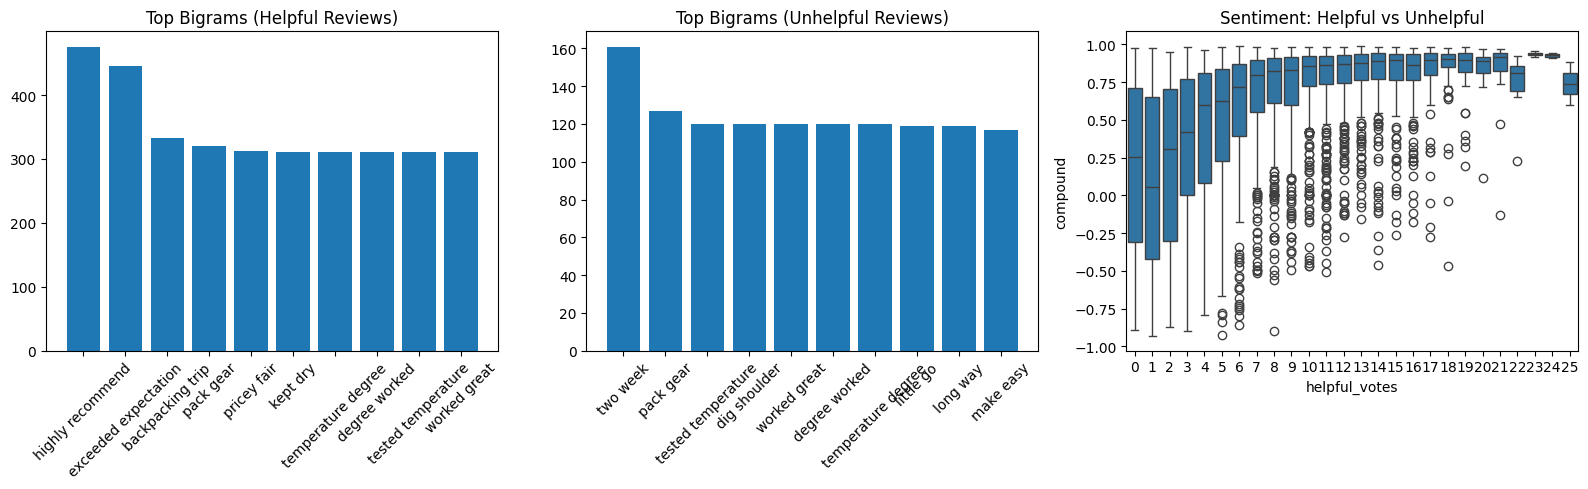

In [172]:
#making the visualizations 

#bar chart to show bigrams 
helpful_bigram_labels = [' '.join(bigram) for bigram in helpful_bigram_freq.index]
unhelpful_bigram_labels = [' '.join(bigram) for bigram in unhelpful_bigram_freq.index] 

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# helpful bigrams 
axes[0].bar(helpful_bigram_labels, helpful_bigram_freq.values)
axes[0].set_title('Top Bigrams (Helpful Reviews)')
axes[0].tick_params(axis='x', rotation=45)

# unhelpful bigrams 
axes[1].bar(unhelpful_bigram_labels, unhelpful_bigram_freq.values)
axes[1].set_title('Top Bigrams (Unhelpful Reviews)')
axes[1].tick_params(axis='x', rotation=45)

# sentiment analysis box plot graph 
sns.boxplot(x='helpful_votes', y='compound', data=product_reviews_df, ax=axes[2])
axes[2].set_title('Sentiment: Helpful vs Unhelpful')

plt.tight_layout()
plt.show()


Based on my analysis, what differentiates 'helpful' and 'unhelpful' reviews linguistically is that helpful votes get higher compound scores and have more opinionated language. Compound scores come from VADER analysis, which uses a bank of words to analyze the overall sentiment of a text. We can see in the top words for helpful versus unhelpful that a lot of the words are the same, so it's not about the individual words that are in the reviews. The VADER analysis also analyzes the bigrams, so if 'great' appears in a review, it could be a bigram of 'not great', and the VADER analysis would count that in it's analysis as negative sentiment, despite having the word 'great' in it. 

Looking at the bigram barcharts, we can see that the top bigrams in helpful reviews are "highly recommend" and "exceeded expectation". These are clearly positive phrases, which contribute to the positive VADER score and more people thinking they are helpful. However, for the negative reviews, the top bigrams are not as obvious. This could be because the unhelpful reviews weren't clear about their opinion, because as we saw earlier, the less extremely positive or negative reviews received less helpful votes. So because these reviews aren't clear about how the person feels about the product, they receive less helpful votes. 

Therefore, what linguistically differentiates the helpful versus unhelpful reviews, based on the analysis I performed, is that helpful reviews include more clear language about how a user feels about the product, while unhelpful reviews include other, perhaps unnessecary information that doesn't give the reader information about how they feel about the product. 